# Data: what we have and how complete it is

**What this answers:** Which data the project uses, how much of it there is, and where it has gaps.

**What it reads:** `data/MANIFEST.json`, the cell-day table and the gap-day table written by the label build, the grid, and the burned-area file.

**What to expect:** A table of datasets, a few plots of detections and gaps, and a short list of known holes.

Load the reporting helpers. They only read saved files and return tables or plots.

In [1]:
from wildfire.reporting import data
from IPython.display import display

**Datasets.** One row per dataset: how many files, how big, and whether it is complete.

In [2]:
display(data.manifest_table())

,dataset,files,size_gb,complete,coverage
0,admin_boundaries,2,0.09,True,to
1,burned_area,2978,0.01,partial,to
2,derived_tables,21,14.03,True,to
3,fire_detections,3183,0.74,True,2018-04-01 to 2025-12-31
4,grid,2,0.01,True,to
5,night_lights,42,5.12,True,2018 to 2024
6,static_layers,5,0.04,True,to
7,vegetation_index,2,0.12,True,to
8,weather_hourly,272,9.03,partial,2017-01 to 2025-12


**Fire detections per year.** The label source. A year with very few detections would be a warning sign.

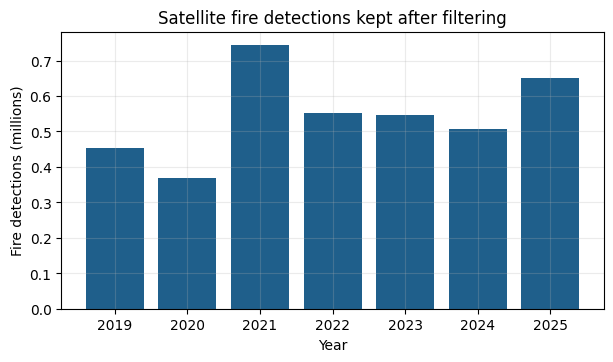

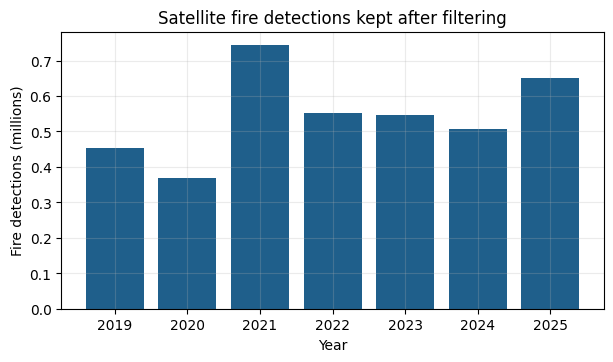

In [3]:
data.plot_detections_by_year()

**Satellite gap days.** On a few days one satellite is missing upstream. Rows near them are dropped, so this table lists them.

,first,last,days
0,2022-07-24,2022-08-08,16
1,2024-05-29,2024-06-02,5


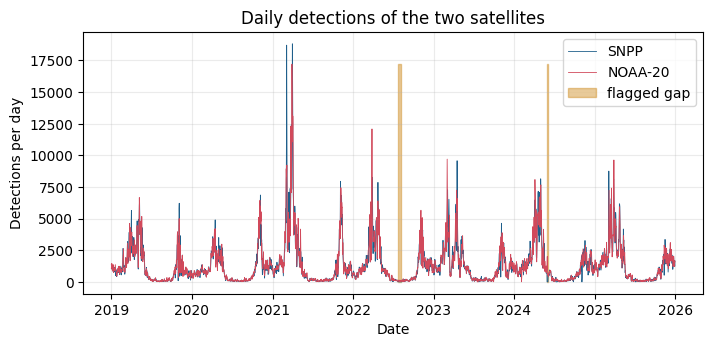

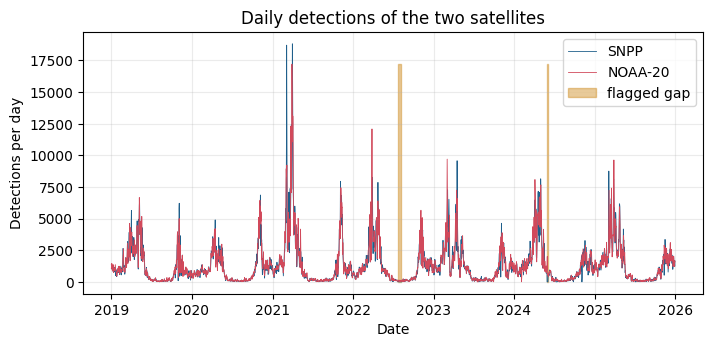

In [4]:
display(data.gap_day_table())
data.plot_gap_days()

**Grid cells by role.** Only cells with the role `train` are used to fit. UK cells are held out for the transfer test.

role,buffer,heldout_UK,reserve,train,unused
state,,,,,
AP,129,0,166,0,6216
CG,38,0,69,5302,0
JH,0,0,0,3196,0
KA,42,0,57,0,0
KL,16,0,8,0,0
MH,121,0,118,12046,0
MP,40,0,6,12295,0
OD,111,0,132,5988,0
TN,30,0,7,0,0


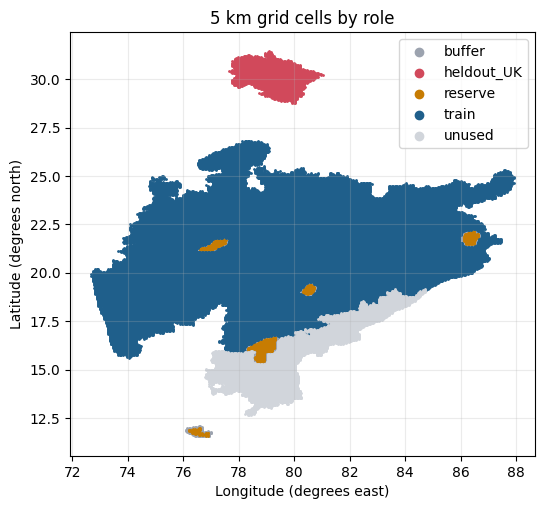

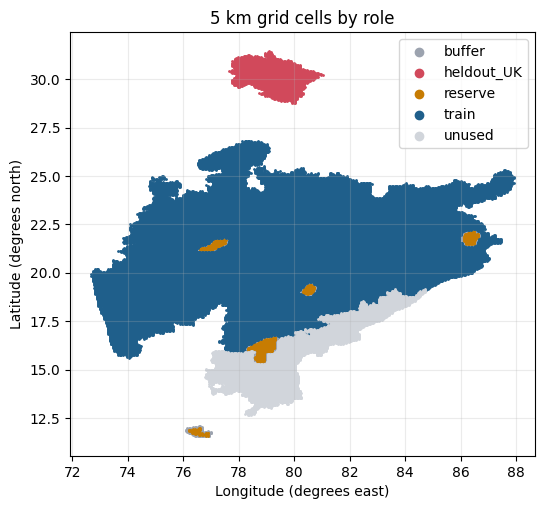

In [5]:
display(data.cell_roles_table())
data.plot_cell_map()

**Burned-area months that are missing.** The product stops in 2025-07, which limits the newest data.

In [6]:
display(data.burn_gap_table())

,month,status
0,2023-09,source_missing
1,2024-07,source_missing
2,2025-05,source_missing
3,2025-08,source_missing
4,2025-09,source_missing
5,2025-10,source_missing
6,2025-11,source_missing
7,2025-12,source_missing


## What this shows

The tables above list what is present, which satellite gaps are flagged and which burned-area months are missing.

## What it does not show

It does not show that detections are a perfect record of fires, or that the weather and land layers are accurate; it only shows what is present.